In [1]:
# ========== 单元格1：身份与环境记录 ==========
import hashlib
import os
import platform
import uuid

# ========= 修改为自己学号 =========
STUDENT_ID = 20244080310
# =================================

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] my_env1
[学号] 20244080310
[机器指纹] af928a2b48f49afb
[RUN_ID] 20244080310-af928a2b48f49afb


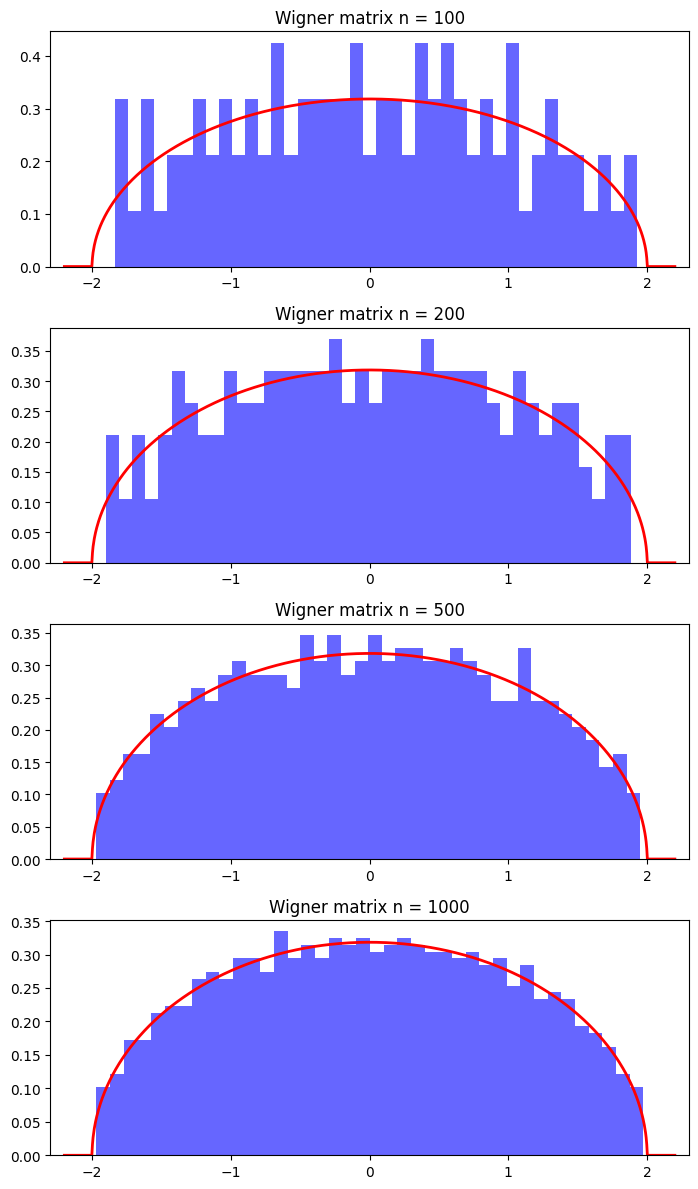

In [2]:
# ========== 单元格2：第一部分 Wigner矩阵 半圆定律 ==========
import numpy as np
import matplotlib.pyplot as plt

# 1. wigner_density
def wigner_density(x):
    if abs(x) <= 2:
        return 1/(2*np.pi) * np.sqrt(4 - x**2)
    else:
        return 0.0

# 2. generate_wigner
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n必须为正整数")
    Z = np.random.normal(loc=0, scale=np.sqrt(1.0/n), size=(n,n))
    # 构造对称矩阵
    Z = np.triu(Z) + np.triu(Z, k=1).T
    return Z

# 3. get_spectrum
def get_spectrum(matrix):
    eigvals = np.linalg.eigvalsh(matrix)
    eigvals_sorted = np.sort(eigvals)
    return eigvals_sorted

# 4. 绘图 n = 100,200,500,1000
fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(7,12))
ns = [100, 200, 500, 1000]
x_curve = np.linspace(-2.2, 2.2, 1000)
y_curve = np.array([wigner_density(x) for x in x_curve])

for ax, n in zip(axes, ns):
    mat = generate_wigner(n)
    spec = get_spectrum(mat)
    ax.hist(spec, bins=40, density=True, color="blue", alpha=0.6)
    ax.plot(x_curve, y_curve, color="red", lw=2)
    ax.set_title(f"Wigner matrix n = {n}")
    ax.set_xlim(-2.3, 2.3)

plt.tight_layout()
plt.show()


初始：
[[0 1 0]
 [0 0 1]
 [1 1 1]]
下一步：
[[0 0 0]
 [0 0 0]
 [0 0 0]]
异常： 无效棋盘：需为二维 ndarray，且元素仅含 0 和 1


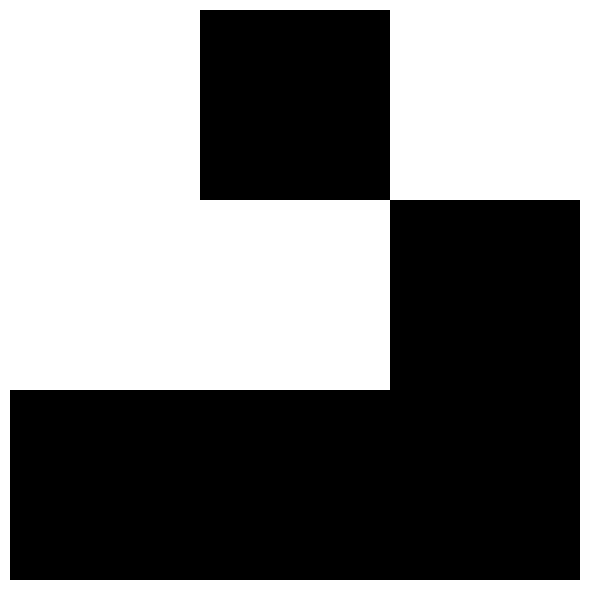

In [3]:
import numpy as np
import matplotlib.pyplot as plt


def is_valid_board(board):
    """校验棋盘：必须是二维 ndarray，元素只能为 0 或 1。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if board.size == 0:                # 空棋盘视为无效
        return False
    return bool(np.all((board == 0) | (board == 1)))


def gol_step(board):
    """计算下一步状态。使用原始棋盘计算邻居；环形边界；同步更新。"""
    if not is_valid_board(board):
        raise ValueError("无效棋盘：需为二维 ndarray，且元素仅含 0 和 1")

    alive = board.astype(bool)                          # 统一成布尔数组

    # —— 环绕边界下统计 8 邻域活细胞数 ——
    neighbors = np.zeros(board.shape, dtype=np.uint8)
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr == 0 and dc == 0:                     # 跳过自身
                continue
            # np.roll 自带循环边界：越界自动绕到对侧
            neighbors += np.roll(np.roll(alive, dr, axis=0), dc, axis=1)

    # —— 同步更新 ——
    # 活细胞：邻居 2 或 3 → 存活；死细胞：邻居恰为 3 → 复活
    new_alive = (neighbors == 3) | (alive & (neighbors == 2))
    return new_alive.astype(np.uint8)


def draw_gol_board(board):
    """可视化：活细胞黑、死细胞白，隐藏网格 / 坐标轴 / 刻度。"""
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(board, cmap="binary", interpolation="nearest",
              vmin=0, vmax=1, aspect="equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.grid(False)
    ax.axis("off")
    for spine in ax.spines.values():
        spine.set_visible(False)
    plt.tight_layout()
    return fig, ax


# ---------------- 演示 ----------------
if __name__ == "__main__":
    glider = np.array([[0, 1, 0],
                       [0, 0, 1],
                       [1, 1, 1]], dtype=np.uint8)

    print("初始：")
    print(glider)
    print("下一步：")
    print(gol_step(glider))

    # 非法棋盘示例
    try:
        gol_step(np.array([[0, 1, 2]]))
    except ValueError as e:
        print("异常：", e)

    draw_gol_board(glider)
    plt.show()

In [4]:
import pandas as pd

df = pd.read_csv("iris.csv", index_col=0)          # 第一列是行号，当索引读进来
MEAS = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]

# 原文件没有种类列，按标准 iris 的固定顺序补：前50 setosa、中50 versicolor、后50 virginica
df["Species"] = ["setosa"] * 50 + ["versicolor"] * 50 + ["virginica"] * 50

print("样本总数：", len(df))
print("各列数据类型：\n", df.dtypes)
print("全部列名：", df.columns.tolist())
print("花卉种类：", df["Species"].unique().tolist())
print("花卉种类数量：", df["Species"].nunique())

df.loc[34, MEAS] = [4.9, 3.1, 1.5, 0.2]     # 第35个数据行，第四项测量改对
df.loc[37, MEAS] = [4.9, 3.6, 1.4, 0.1]     # 第38个数据行，第二、三项测量改对

print(df.loc[[34, 37], MEAS])
print("这两行还有缺失值吗：", bool(df.loc[[34, 37], MEAS].isna().any().any()))
df["Petal.Ratio"] = df["petal length (cm)"] / df["petal width (cm)"]
df["Sepal.Ratio"] = df["sepal length (cm)"] / df["sepal width (cm)"]

print(df[["Petal.Ratio", "Sepal.Ratio"]].head())

df.to_csv("iris_corrected.csv", index=False)

stats = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(stats)


样本总数： 150
各列数据类型：
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
Species                  str
dtype: object
全部列名： ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'Species']
花卉种类： ['setosa', 'versicolor', 'virginica']
花卉种类数量： 3
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
34                4.9               3.1                1.5               0.2
37                4.9               3.6                1.4               0.1
这两行还有缺失值吗： False
   Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750
3          7.5     1.483871
4          7.0     1.388889
           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
Species                                                                  
setosa        6.908000  7.0000